# Lab 27-07 · Racks, Collectives, Failures and Tokens

Companion to [chapter 27-07](../../chapters/27-07-ai-datacenter-server-and-rack.md). Every part asks you to **predict first**, then run. All parameters are the chapter's assumptions unless a source is cited there.

In [1]:
import sys, math
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, '.')
import rackmodel as rm

## Part 1 · The size of the scale-up domain

Example 27-07.4: 10 GB of gradients on 1,152 GPUs, NVLink 900 GB/s per direction, network 100 GB/s per GPU. With 72-GPU racks the hierarchical all-reduce takes 24.5 ms.

**Predict:** the time if the same GPUs come in 8-GPU servers (144 of them).

In [2]:
S = 10e9
for p1 in (72, 8):
    inside, across, total = rm.hierarchical_allreduce_s(S, p1, 900e9, 1152 // p1, 100e9)
    print(f"domain {p1:3d}: inside {1e3*inside:5.1f} ms, across {1e3*across:5.1f} ms, total {1e3*total:5.1f} ms")

domain  72: inside  21.9 ms, across   2.6 ms, total  24.5 ms
domain   8: inside  19.4 ms, across  24.8 ms, total  44.3 ms


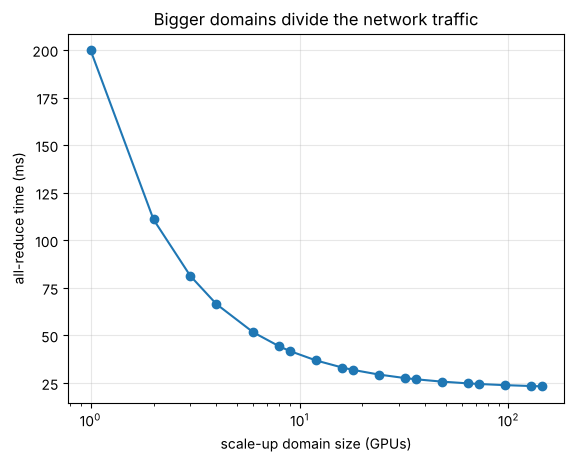

In [3]:
sizes = [d for d in range(1, 1153) if 1152 % d == 0 and d <= 144]
tot = [1e3 * rm.hierarchical_allreduce_s(S, d, 900e9, 1152 // d, 100e9)[2] if d > 1
       else 1e3 * rm.ring_allreduce_s(S, 1152, 100e9) for d in sizes]
plt.plot(sizes, tot, 'o-')
plt.xscale('log'); plt.xlabel('scale-up domain size (GPUs)'); plt.ylabel('all-reduce time (ms)')
plt.title('Bigger domains divide the network traffic'); plt.grid(True, alpha=0.3); plt.show()

## Part 2 · A bigger job

Example 27-07.5: one unexpected interruption every 3.09 h on 16,384 GPUs; 60 s saves, 10-minute restarts.

**Predict:** Young's interval and the effective training time at 32,768 GPUs.

In [4]:
M = 54 * 86400 / 419
for n in (16384, 32768):
    Mn = M * 16384 / n
    tau = rm.young_interval_s(60, Mn)
    lost = rm.lost_fraction(tau, 60, Mn, 600)
    print(f"{n} GPUs: M = {Mn:.0f} s, tau* = {tau:.0f} s ({tau/60:.1f} min), effective {100*(1-lost):.1f}%")

16384 GPUs: M = 11135 s, tau* = 1156 s (19.3 min), effective 84.2%
32768 GPUs: M = 5568 s, tau* = 817 s (13.6 min), effective 74.5%


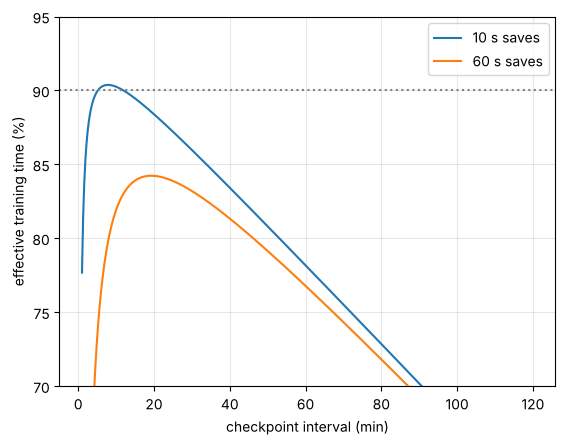

In [5]:
tau = np.linspace(60, 7200, 400)
for d in (10, 60):
    plt.plot(tau / 60, [100 * (1 - rm.lost_fraction(t, d, M, 600)) for t in tau], label=f'{d} s saves')
plt.axhline(90, color='0.5', ls=':')
plt.ylim(70, 95); plt.xlabel('checkpoint interval (min)'); plt.ylabel('effective training time (%)')
plt.legend(); plt.grid(True, alpha=0.3); plt.show()

## Part 3 · The frontier

Example 27-07.6: a 10¹²-parameter MoE model at 4 bits (0.5 TB), 4 × 10¹⁰ active parameters, 0.8 GB of KV cache per sequence, a rack with 576 TB/s (50% achieved), 13.4 TB and 720 PFLOP/s.

**Predict:** step time, throughput and per-user speed at B = 1024.

In [6]:
W, K, BW, ETA, NACT, F4 = 0.5e12, 0.8e9, 576e12, 0.5, 4e10, 720e15
for b in (256, 1024):
    s, tm, tc = rm.decode_step_s(b, W, K, BW, ETA, NACT, F4)
    print(f"B = {b}: step {1e3*s:.2f} ms, throughput {b/s:.3g} tokens/s, per user {1/s:.0f} tokens/s")

B = 256: step 2.45 ms, throughput 1.05e+05 tokens/s, per user 409 tokens/s
B = 1024: step 4.58 ms, throughput 2.24e+05 tokens/s, per user 218 tokens/s


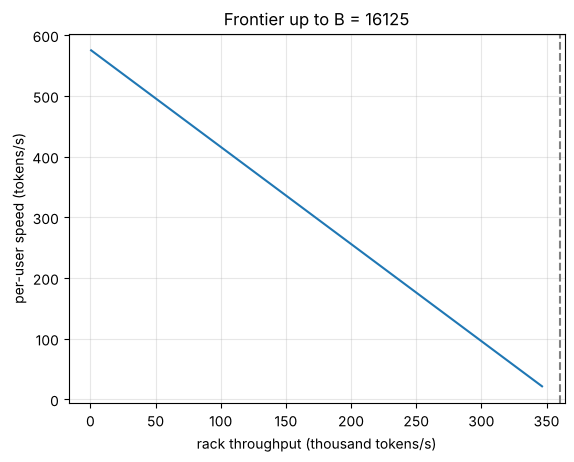

In [7]:
bmax = rm.max_batch(13.4e12, W, K)
bs = np.unique(np.round(np.logspace(0, math.log10(bmax), 200)).astype(int))
thr = [b / rm.decode_step_s(b, W, K, BW, ETA, NACT, F4)[0] for b in bs]
usr = [1 / rm.decode_step_s(b, W, K, BW, ETA, NACT, F4)[0] for b in bs]
plt.plot(np.array(thr) / 1e3, usr)
plt.axvline(ETA * BW / K / 1e3, ls='--', color='0.5')
plt.xlabel('rack throughput (thousand tokens/s)'); plt.ylabel('per-user speed (tokens/s)')
plt.title(f'Frontier up to B = {bmax}'); plt.grid(True, alpha=0.3); plt.show()

## Part 4 · What drives token cost?

Example 27-07.6(e): $3.0 M over 4 years, 130 kW, PUE 1.2, 60% utilization, B = 256.

**Predict:** the cost per million tokens at $0.16/kWh instead of $0.08/kWh.

In [8]:
thr256 = 256 / rm.decode_step_s(256, W, K, BW, ETA, NACT, F4)[0]
for price in (0.08, 0.16):
    c = rm.cost_per_million_tokens(3e6, 4, 130, 1.2, price, thr256, 0.6)[0]
    print(f"${price:.2f}/kWh: ${c:.3f} per million tokens")

$0.08/kWh: $0.434 per million tokens
$0.16/kWh: $0.489 per million tokens


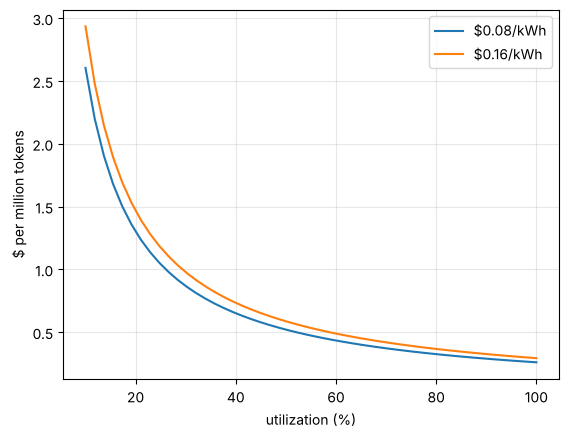

In [9]:
u = np.linspace(0.1, 1.0, 50)
for price in (0.08, 0.16):
    plt.plot(100 * u, [rm.cost_per_million_tokens(3e6, 4, 130, 1.2, price, thr256, x)[0] for x in u],
             label=f'${price:.2f}/kWh')
plt.xlabel('utilization (%)'); plt.ylabel('$ per million tokens'); plt.legend(); plt.grid(True, alpha=0.3); plt.show()

## Discussion

Compare your predictions with the lab README's expected results. Which lever moved each answer most: the scale-up domain, the save and restart times, the batch, or utilization?